    Single allele groupped structue models.

In [3]:
import pomegranate.io
from pomegranate import *

In [4]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


In [5]:
import training_parameters
from peptides_utils import defineClass, defineOrganism, make_logo_for_data
from data_reading_methods import remove_unused_lengths, transform_data_to_properties_and_join_alleles, calculate_weights_based_on_length_counts

# 1. Read data

In [6]:
hmm_params = training_parameters.ExperimentParams(experiment_name="split_mixmhc")
hmm_params.model_training_params = training_parameters.SimpleModelClassIIParamsMixMHC()
hmm_params.data_scenario_params = training_parameters.MixMHCpredDataParams()


In [7]:
hmm_params.data_scenario_params

MixMHCpredDataParams(data_path_base='G:\\My Drive\\Work\\ITMO\\data', data_scenario='MixMHCpred', dummy_allele_name='mixMHC_dummy_allele', input_data_path='G:\\My Drive\\Work\\ITMO\\data\\Binding data\\MixMHC2pred_2023\\train_data\\external_studies.csv', mixmhc_mixture_name='CD165_DR', name='MixMHCpredDataParams00016', splits_to_read=1)

In [8]:
model_training_params = hmm_params.model_training_params

In [9]:
from data_reading_methods import get_available_alleles, get_train_test_data, join_dicts

per_allele_per_kfold_per_length_binders_train, \
per_allele_per_kfold_per_length_binders_test, additional_data = get_train_test_data(hmm_params)

PARSED_ALLELES = list(per_allele_per_kfold_per_length_binders_train.keys())

print(sorted(PARSED_ALLELES))

Will read files from the folder G:\My Drive\Work\ITMO\data\Binding data\MixMHC2pred_2023\train_data\external_studies.csv
Index(['Peptide', 'pepL', 'geneName', 'Nterm', 'Cterm', 'Sample_IDs', 'Allele',
       'multiSpec', 'Core', 'CoreOffset'],
      dtype='object')
['d_CD165_DR']


# 2. Prepare data and weithgs for training

In [10]:
df = additional_data[0][list(additional_data[0].keys())[0]]

In [11]:
model_training_params: training_parameters.ModelTrainingParams = hmm_params.model_training_params
#model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in ['HLA-DRB1*04:01']]
current_mix = PARSED_ALLELES[0]
model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in [current_mix]]
#model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in ['decoy-allele-78']]
# remove unused lengths (used are specified in ModelTrainingParams.model_training_params
per_allele_per_kfold_per_length_binders_train = remove_unused_lengths(per_allele_per_kfold_per_length_binders_train, experiment_params=hmm_params)
per_allele_per_kfold_per_length_binders_test = remove_unused_lengths(per_allele_per_kfold_per_length_binders_test,experiment_params=hmm_params)

# transform to properties if needed and join multiple alleles
train_data, test_data, NEW_ALLELES, \
old_train_data, old_test_data, OLD_ALLELES = transform_data_to_properties_and_join_alleles(
    per_allele_per_kfold_per_length_binders_train,
    per_allele_per_kfold_per_length_binders_test,
    hmm_params.model_training_params
)
# Calculate weights for the training data based on peptide couns/lengths for unmerged data
train_data_weigths = calculate_weights_based_on_length_counts(old_train_data, experiment_params=hmm_params)

d_CD165_DR
Length 16: d_CD165_DR - 978 
Length 17: d_CD165_DR - 755 
Length 18: d_CD165_DR - 461 
Length 12: d_CD165_DR - 193 
Length 13: d_CD165_DR - 536 
Length 14: d_CD165_DR - 936 
Length 15: d_CD165_DR - 1118 


## Check: Motif for train data

In [12]:
train_data.keys()

dict_keys(['d_CD165_DR'])

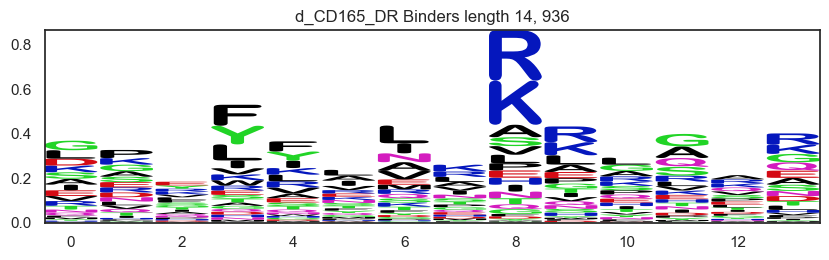

In [13]:
target_allele = hmm_params.model_training_params.alleles_to_use[0]
target_length = hmm_params.model_training_params.lengths_to_use[2]
peptides = train_data[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# 3. Models

In [14]:
import random

random.seed(10)

from hmm_logic_methods import train_model_prepared,  \
    train_model_batched, save_model, \
    add_more_states_and_reset_transitions, \
    build_model_based_on_params, \
    prepare_multiple_models, train_multiple_models, \
reorder_models_by_score_and_flatten_to_by_name_list, hierarchically_train_splited_models
from hmm_visualization_methods import *

C:\Users\denkl\AppData\Roaming\Python\Python39\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Check generate sample model to ensure that it is looking like we want

In [15]:
prepared_model = build_model_based_on_params(hmm_params.model_training_params, verbose=True)

with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

plot_distributions_for_states(prepared_model,"test", horizontal=False,
                              discrete = hmm_params.model_training_params.aa_labels_training,
                              initial_params = hmm_params.model_training_params.initial_params)
make_pyviz_graph(prepared_model, "test", precision=3)

start cycles added 1
end cycles added 1
states will be groups:7 + joiners:2 + start/end cycles:2 + int_cycles:0
One more time number of 'cycle' states 1 1
For example start cycle states [9]


<class 'pyvis.network.Network'> |N|=13 |E|=16

## Prepare and train models

In [16]:
#prepare models
per_allele_per_run_per_split_prepared_models = prepare_multiple_models(hmm_params)
#do training

orig_std = sys.stdout
with open('out_root.txt', 'w') as f:
    sys.stdout = f
    result_models, \
    result_histories =  train_multiple_models(
        prepared_models=per_allele_per_run_per_split_prepared_models,
        train_data=train_data,
        test_data=test_data,
        train_data_weigths=train_data_weigths,
        experiment_params=hmm_params,
        subfolder_to_safe_result="root")
sys.stdout = orig_std

In [17]:
per_name_models, per_name_histories, original_alelle_sortings = reorder_models_by_score_and_flatten_to_by_name_list(histories=result_histories,
                                                                models=result_models, experiment_params=hmm_params,subfolder_to_safe_result="root" )
save_all_visualization_results(per_name_models, per_name_histories, experiment_params=hmm_params, subfolder_to_safe_result="root")


ModelGraph
0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 
Distributions
0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 
PyViz


Model root[0049]_run-7-st-v-alg-40-min_iters-12-18_model-d_CD165_DR-0
Get viterbi paths for each peptide...


100%|██████████| 4977/4977 [00:00<00:00, 58329.26it/s]


Subselect unique paths (if unique path argument passed)..
	Unique paths: 4977 


100%|██████████| 4977/4977 [00:00<00:00, 19710.66it/s]


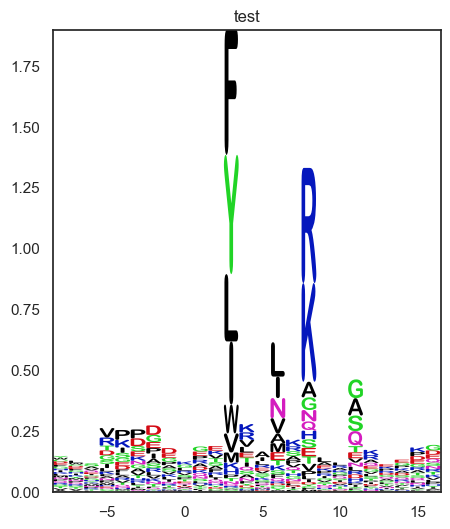

In [18]:
import importlib
import hmm_logic_methods
import logomaker
from peptides_utils import get_frequencies
hmm_logic_methods= importlib.reload(hmm_logic_methods)
from hmm_logic_methods import check_model_alignment, init_distribution
allele_data_df = join_dicts(train_data)[PARSED_ALLELES[0]]

info_matrix = check_model_alignment(per_name_models[list(per_name_models.keys())[49]], allele_data_df)



In [19]:
from hmm_logic_methods import get_information_content_estimation_for_models
statistics_estimate_models_fraction = model_training_params.statistics_estimate_model_fraction

name_to_info_value, allele_to_info_matrix, allele_to_info_value = get_information_content_estimation_for_models(per_name_models, models_fraction=statistics_estimate_models_fraction)
model_name_to_allele = {
    model_name : f"{model_name.split('-')[-2]}" for model_name in per_name_models.keys()
}
path_to_save_pictures = f"{hmm_params.experiment_result_data_path}"
info_threshold = model_training_params.trash_model_information_threshold
passed_filter = {key for key, info_value in name_to_info_value.items() if info_value > info_threshold}
print(f"For root {len(passed_filter)} models passed the info filter out of {len(per_name_models)}")
for allele_name in allele_to_info_matrix.keys():
    info_value =allele_to_info_value[allele_name]
    passed = info_value > info_threshold
    main_title = f"Allele {allele_name} \n  info ({np.round(info_value,2)}) passed ({passed})"
    filename=f"{allele_name}-split-root.svg"
    fig, ax = plt.subplots(ncols      =1, nrows=1, figsize=(5, 3))
    ww_logo = logomaker.Logo(allele_to_info_matrix[allele_name], font_name='Arial Rounded MT Bold', flip_below=True,
                             ax=ax)
    ww_logo.ax.set_title(f"branch")
    fig.suptitle(main_title)
    plt.tight_layout()
    save_figure_to_svg(fig, dir=path_to_save_pictures, filename=f"{filename}.svg")
    plt.close(fig)


For information content 10 will be summarized
check how many models we added at the end: defaultdict(<class 'int'>, {'d_CD165_DR': 10})
info calculated  {'d_CD165_DR': 0.6466875462105154}
For root 50 models passed the info filter out of 50


# Splitting

CPU times: total: 25min 37s
Wall time: 24min 58s


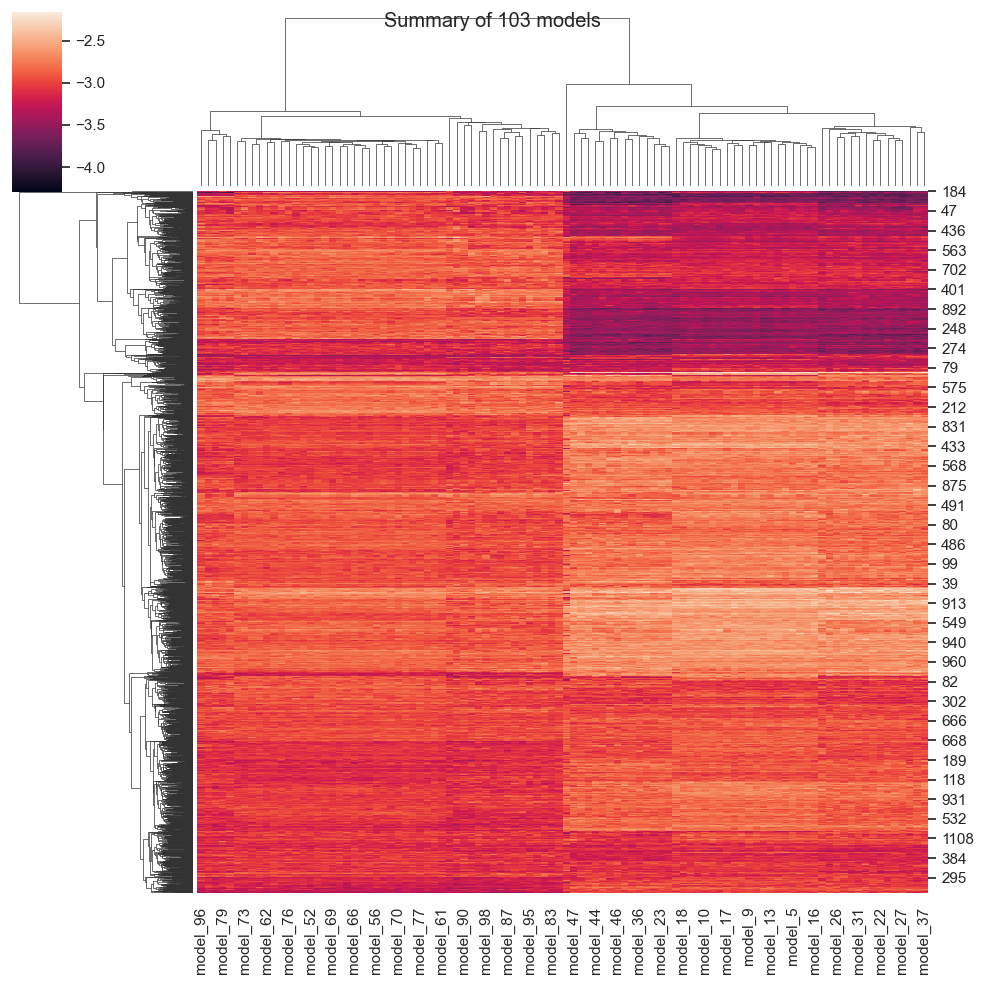

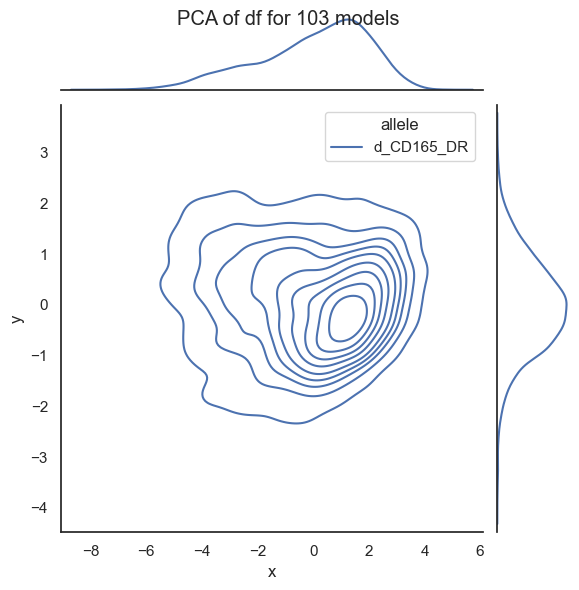

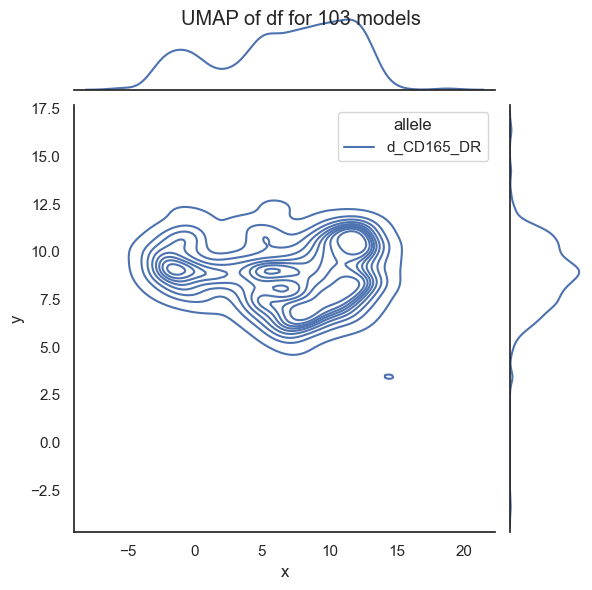

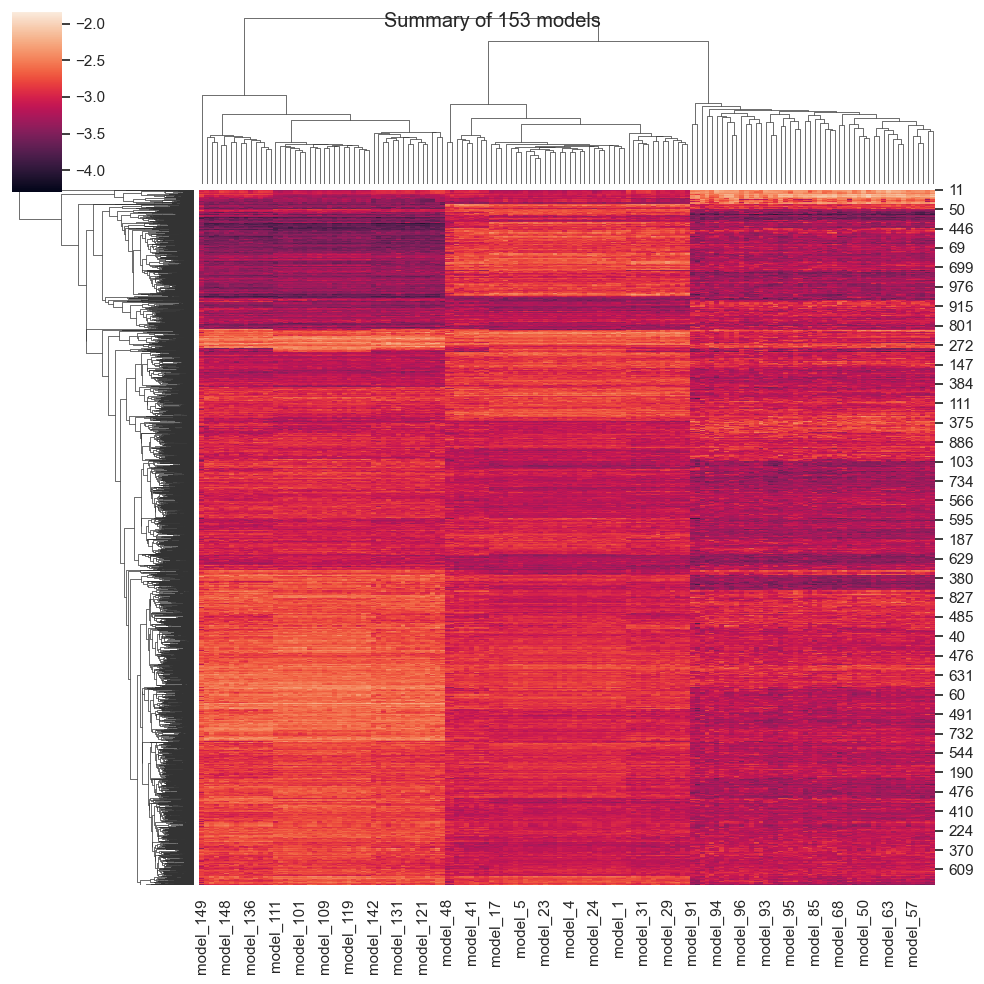

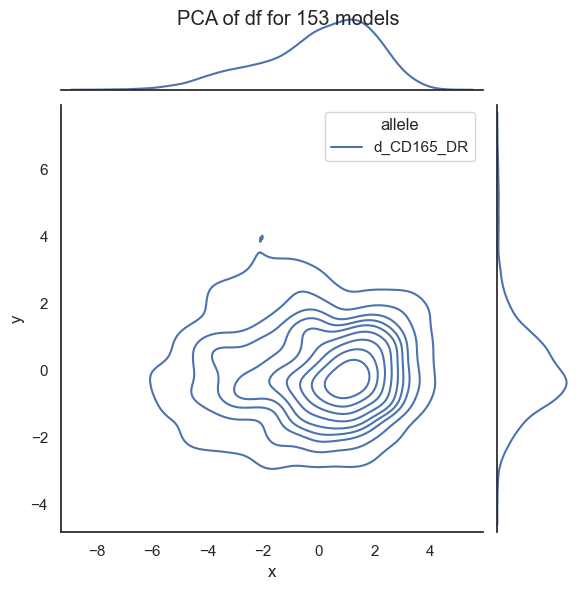

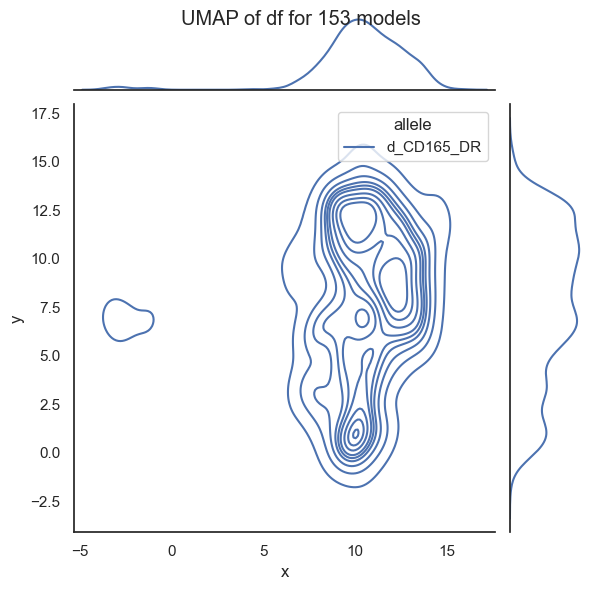

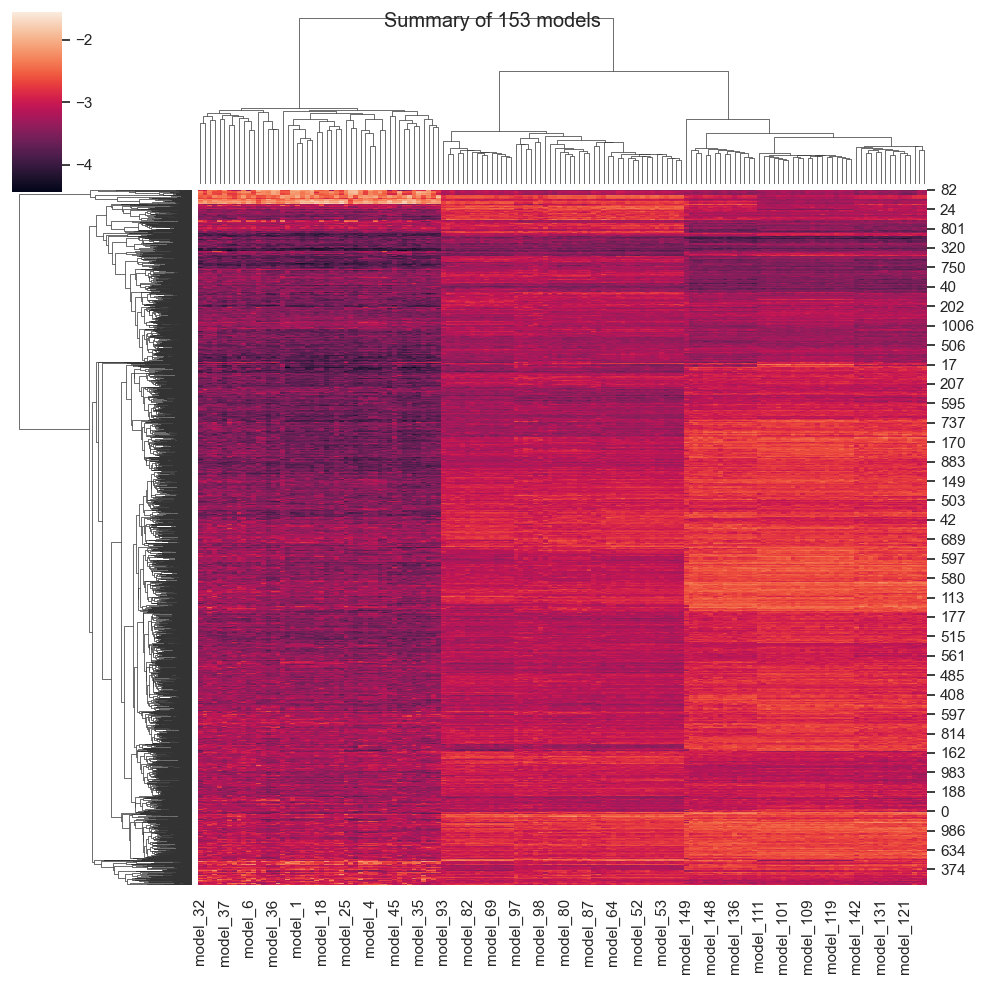

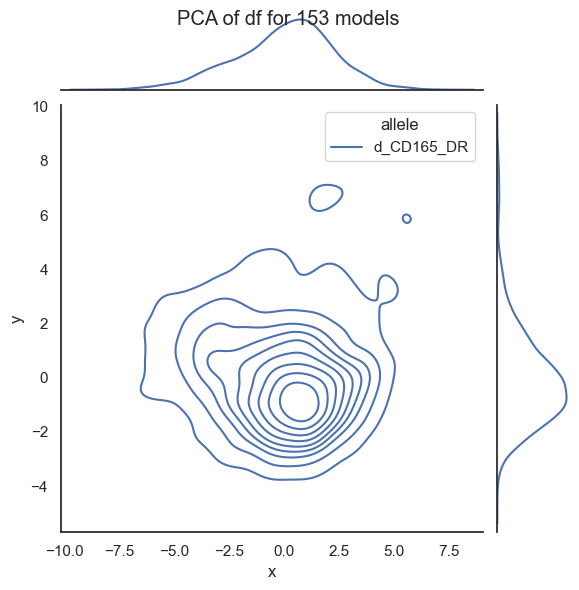

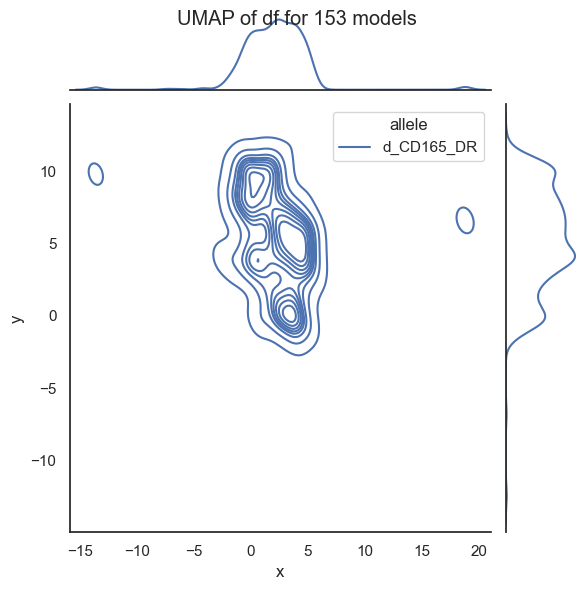

In [20]:
%%time
import sys
orig_std = sys.stdout
with open('out_split.txt', 'w') as f:
    sys.stdout = f
    hierarchically_train_splited_models(per_name_models=per_name_models,
                                        train_data=train_data,
                                        test_data=test_data,
                                        additional_data=additional_data,
                                        experiment_params=hmm_params,
                                        total_layers_to_do=3)
sys.stdout = orig_std

In [21]:
per_name_models[list(per_name_models.keys())[0]].states[0].name

's000'

In [22]:
per_allele_data_df = join_dicts(train_data)